# One decision a week — the brief's literal reading

The brief asks for a model that predicts *"the optimal action (Buy, Sell, or Hold) … over a defined future horizon (e.g., the next 5 trading days)"*. Every version so far makes that prediction **every day** and acts on it daily, so neighbouring 5-day windows overlap. This notebook re-runs every version with **one decision a week**:

> After the close on the last trading day of the week (normally Friday), the model predicts Buy, Hold or Sell for the next 5 trading days. The trade fills at the next open (normally Monday), and the position is held all week. **Buy** → invested, **Sell** → cash, **Hold** → keep last week's position.

**What does not change:** the models, their settings, the labels, the costs and the cash assumptions. Every model is used exactly as frozen. v1 and v2 use their saved test predictions; v3 and the walk-forward recompute the same frozen fits. Only the decision schedule changes.

**Disclosure.** This check was decided **after** all test results were known. It is a sensitivity analysis on already-seen data, not a new selection: no model, threshold or rule is chosen from it. Each daily row first reproduces the published result exactly, so the weekly row differs only by schedule.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, v2, v3, weekly
from src.backtest import to_positions
from src.data import load_snapshot
from src.dataset import build_dataset_v2

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.OUTPUT_DIR / "weekly"; (OUT / "figures").mkdir(parents=True, exist_ok=True)

raw = load_snapshot(); px = raw[["Open", "Close"]]
rf = v2.load_tbill_daily(raw.index)
HOLD = config.ROOT / "data" / "holdout"
raw_h = pd.read_csv(HOLD / "spy_20261013.csv", index_col=0, parse_dates=True); px_h = raw_h[["Open", "Close"]]
rf_h = v2.load_tbill_daily(raw_h.index, HOLD / "irx_20261013.csv")

ROWS, PATHS = [], {}
def run(version, period, schedule, held, prices, rf_seg, cash, random_n=1000):
    sim = v2.simulate(held, prices.loc[held.index], rf_seg)
    s = v2.summarize(sim, held, rf_seg, "")
    pct = None
    if s["round_trips"] > 1 and random_n:
        rand = v2.random_timing_benchmark(held, prices.loc[held.index], rf_seg, n=random_n)
        pct = round(float((rand < sim["value"].iloc[-1]).mean()), 3)
    decisions = len(weekly.week_end_days(held.index)) if schedule == "weekly" else len(held)
    ROWS.append({"version": version, "period": period, "schedule": schedule, "cash": cash,
                 "final_value": s["final_value"], "round_trips": s["round_trips"], "exposure": s["exposure"],
                 "fees": s["total_fees"], "sharpe_excess": s["sharpe_excess"], "max_drawdown": s["max_drawdown"],
                 "beats_random_pct": pct, "decision_days": decisions})
    PATHS[(version, period, schedule)] = sim["value"]
    return s["final_value"]

def bh(period, prices, rf_seg, cash, index):
    held = v2.buy_and_hold_held(index)
    return run("Buy & Hold", period, "—", held, prices, rf_seg, cash, random_n=0)

## v1 · random forest, Buy/Sell rule (cash earns 0%, as in v1)

In [2]:
for period, f in [("2021–22 validation", "val_predictions.csv"), ("2023–24 test", "test_predictions.csv")]:
    pr = pd.read_csv(config.OUTPUT_DIR / f, index_col=0, parse_dates=True)
    daily = v2.held_from_positions(to_positions(pr["action"], min_hold=5))
    week = v2.held_from_positions(weekly.weekly_positions_from_actions(pr["action"], start=0))
    d = run("v1", period, "daily", daily, px, None, "0%")
    run("v1", period, "weekly", week, px, None, "0%")
    bh(period, px, None, "0%", pr.index)
    print(period, f"daily reproduces v1: ${d:,.0f}")
assert round(ROWS[3]["final_value"]) == 123714, "v1 daily test must reproduce v1's published $123,714"

2021–22 validation daily reproduces v1: $99,809


2023–24 test daily reproduces v1: $123,714


## v2 · gradient boosting, expected-return rule, default-long (cash earns T-bills)

In [3]:
p2 = pd.read_csv(config.OUTPUT_DIR / "v2" / "test_predictions.csv", index_col=0, parse_dates=True)
er2 = p2["E_r"]
daily = v2.held_from_positions(v2.positions_from_er(er2, "long"), start=1)
assert (daily == p2["held"]).all(), "v2 daily positions must match v2's saved positions"
week = v2.held_from_positions(weekly.weekly_positions_from_er(er2, "long"), start=1)
d = run("v2", "2023–24 test", "daily", daily, px, rf.loc[er2.index], "T-bills")
run("v2", "2023–24 test", "weekly", week, px, rf.loc[er2.index], "T-bills")
bh("2023–24 test", px, rf.loc[er2.index], "T-bills", er2.index)
assert round(d) == 121812, d
print(f"daily reproduces v2: ${d:,.0f}")

# 12-year walk-forward: v2's frozen fit refit each January (identical to v3's C0 treatment)
ds = build_dataset_v2(raw)
er_wf = v3.expected_return(v3.walk_forward_proba(ds, "C0", list(range(2013, 2025)), v3.v2_params()))
daily = v2.held_from_positions(v2.positions_from_er(er_wf, "long"), start=1)
week = v2.held_from_positions(weekly.weekly_positions_from_er(er_wf, "long"), start=1)
d = run("v2", "2013–24 walk-forward", "daily", daily, px, rf.loc[er_wf.index], "T-bills", random_n=200)
run("v2", "2013–24 walk-forward", "weekly", week, px, rf.loc[er_wf.index], "T-bills", random_n=200)
bh("2013–24 walk-forward", px, rf.loc[er_wf.index], "T-bills", er_wf.index)
print(f"daily walk-forward reproduces v2: ${d:,.0f}")
assert round(d) == 179977, d

daily reproduces v2: $121,812


daily walk-forward reproduces v2: $179,977


## v3 · calibrated odds, default-long (frozen C3-L; cash earns T-bills)

In [4]:
params = v3.v2_params()
for period, data, prices, rfs, years in [("2023–24 test", ds, px, rf, [2023, 2024]),
                                         ("2025–26 holdout", build_dataset_v2(raw_h), px_h, rf_h, [2025, 2026])]:
    er3 = v3.expected_return(v3.walk_forward_proba(data, "C3", years, params))
    daily = v2.held_from_positions(v2.positions_from_er(er3, "long"), start=1)
    week = v2.held_from_positions(weekly.weekly_positions_from_er(er3, "long"), start=1)
    run("v3", period, "daily", daily, prices, rfs.loc[er3.index], "T-bills")
    run("v3", period, "weekly", week, prices, rfs.loc[er3.index], "T-bills")
    bh(period, prices, rfs.loc[er3.index], "T-bills", er3.index)

## All results

In [5]:
res = pd.DataFrame(ROWS)
res["vs_buy_and_hold"] = res["final_value"] - res.groupby(["period", "cash"])["final_value"].transform(
    lambda s: s[res.loc[s.index, "version"] == "Buy & Hold"].iloc[0])
order = ["version", "period", "schedule", "final_value", "vs_buy_and_hold", "round_trips", "exposure", "fees",
         "sharpe_excess", "max_drawdown", "beats_random_pct", "decision_days", "cash"]
res = res[order]
display(res.style.format({"final_value": "${:,.0f}", "vs_buy_and_hold": "${:+,.0f}", "fees": "${:,.0f}",
                          "exposure": "{:.0%}", "sharpe_excess": "{:.2f}", "max_drawdown": "{:.1%}"}, na_rep="—"))

,version,period,schedule,final_value,vs_buy_and_hold,round_trips,exposure,fees,sharpe_excess,max_drawdown,beats_random_pct,decision_days,cash
0,v1,2021–22 validation,daily,"$99,809","$-4,964",13,51%,"$2,728",0.07,-17.2%,0.555000,503,0%
1,v1,2021–22 validation,weekly,"$93,902","$-10,871",9,51%,"$1,733",-0.12,-21.7%,0.313000,104,0%
2,Buy & Hold,2021–22 validation,—,"$104,773",$+0,1,100%,$100,0.22,-24.5%,—,503,0%
3,v1,2023–24 test,daily,"$123,714","$-32,833",15,58%,"$3,237",1.14,-9.6%,0.449000,502,0%
4,v1,2023–24 test,weekly,"$124,654","$-31,892",6,61%,"$1,229",1.13,-8.7%,0.388000,105,0%
5,Buy & Hold,2023–24 test,—,"$156,546",$+0,1,100%,$100,1.82,-10.0%,—,502,0%
6,v2,2023–24 test,daily,"$121,812","$-34,734",17,53%,"$3,754",0.59,-10.0%,0.264000,502,T-bills
7,v2,2023–24 test,weekly,"$123,834","$-32,713",9,52%,"$1,988",0.69,-9.9%,0.179000,105,T-bills
8,Buy & Hold,2023–24 test,—,"$156,546",$+0,1,100%,$100,1.43,-10.0%,—,502,T-bills
9,v2,2013–24 walk-forward,daily,"$179,977","$-319,294",112,60%,"$27,257",0.35,-22.4%,0.320000,3020,T-bills


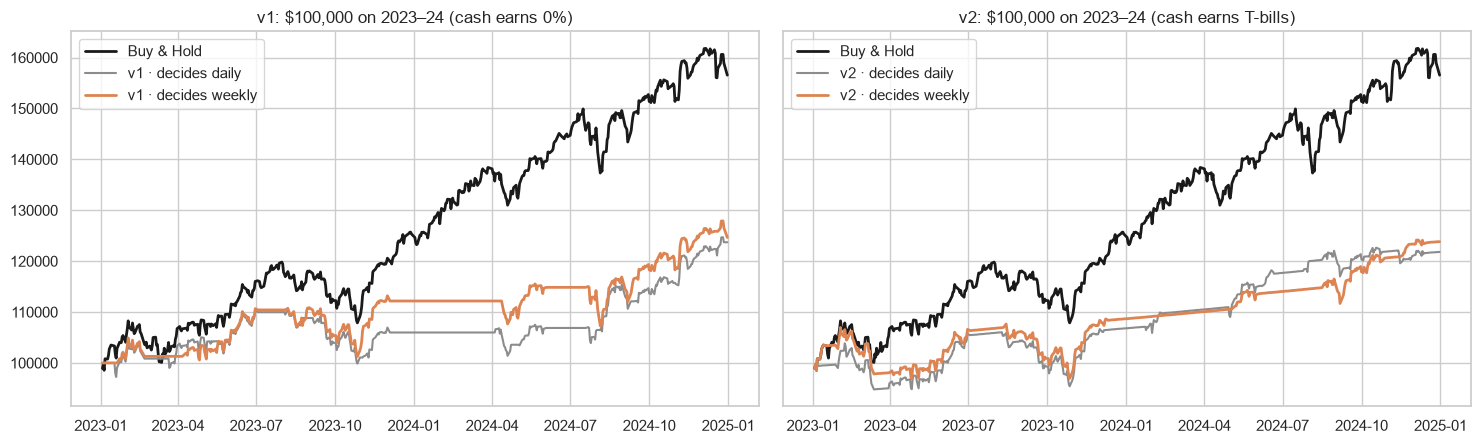

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for j, v in enumerate(["v1", "v2"]):
    cash = "0%" if v == "v1" else "T-bills"
    ax[j].plot(PATHS[("Buy & Hold", "2023–24 test", "—")], color="k", lw=2, label="Buy & Hold")
    ax[j].plot(PATHS[(v, "2023–24 test", "daily")], color="0.55", lw=1.5, label=f"{v} · decides daily")
    ax[j].plot(PATHS[(v, "2023–24 test", "weekly")], color="C1", lw=2, label=f"{v} · decides weekly")
    ax[j].set_title(f"{v}: $100,000 on 2023–24 (cash earns {cash})"); ax[j].legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "daily_vs_weekly_2023_24.png", dpi=120, bbox_inches="tight"); plt.show()

## Save

In [7]:
out = json.loads(res.to_json(orient="records"))
(OUT / "results.json").write_text(json.dumps(out, indent=2))
print("saved outputs/weekly/results.json and figures/")

saved outputs/weekly/results.json and figures/
